# COPD Detection from Chest X-rays: Baseline vs. Attention-Enhanced Pretrained CNN (with PADA)

**What this notebook does (end to end, resumable):**
1. Builds an **age- and view-matched** COPD (emphysema-phenotype) vs. Normal dataset from NIH ChestX-ray14 (Kaggle `nih-chest-xrays/data`, CC0, free).
2. **Patient-level** train/val/test split + leakage audit (patient overlap, near-duplicate check).
3. Trains a **justified baseline** (ImageNet ResNet-50) and an **ablation ladder** (+SE, +CBAM, +SE+CBAM, +SA, +PADA ...) for **50 epochs, no early stopping** (best-val-AUC checkpoint is *selected*, training never stops early).
4. Evaluates with AUC, AP, Acc, Bal-Acc, Sens, Spec, F1, MCC, Brier, ECE + params / FLOPs / latency, multi-seed mean ± std, paired-bootstrap significance, Grad-CAM.
5. Saves everything to one dedicated Google Drive folder.

**Proposed novelty - PADA (Position-Aware Dual-Axis Attention):** self-attention along the vertical and horizontal axes separately, with *learned absolute-position embeddings* and an adaptive axis-fusion gate. COPD/emphysema cues (hyperinflation, flattened diaphragm, increased lung height, widened intercostal spaces) are *anisotropic and position-dependent*; plain non-local self-attention is permutation-equivariant and position-blind.

> Results are whatever the data gives. Nothing here is tuned to force the proposed model to win. Check the `tables/` and `figures/` folders and report them honestly.

In [ ]:
# ===== 1. SETUP =====
!pip -q install kaggle opencv-python-headless seaborn
import os, sys, json, math, time, random, shutil, zipfile, warnings, platform, glob
from pathlib import Path
import numpy as np, pandas as pd
warnings.filterwarnings('ignore')

from google.colab import drive, userdata
drive.mount('/content/drive')

CFG = dict(
    RUN_NAME      = 'copd_nih_emphysema_v1',
    DRIVE_ROOT    = '/content/drive/MyDrive/COPD_Paper_Experiments',
    SEED          = 42,           # data split / sampling seed (fixed for ALL models)
    IMG_STORE     = 352,          # cached resolution
    IMG_SIZE      = 320,          # network input (random-crop/affine from 352)
    BATCH         = 32,
    EPOCHS        = 50,           # NO early stopping
    BACKBONE      = 'resnet50',   # use 'resnet18' for ~3x faster runs
    NEG_PER_POS   = 2,            # matched controls per COPD image
    AGE_MIN       = 30, AGE_MAX = 95,
    LR_BACKBONE   = 1e-4, LR_NEW = 1e-3, WD = 0.05, WARMUP_EPOCHS = 3,
    LABEL_SMOOTH  = 0.05, DROPOUT = 0.3, GRAD_CLIP = 1.0,
    ABLATION_SEEDS= [42],               # seeds for the full ablation ladder
    MAIN_SEEDS    = [42, 1337, 2024],   # extra seeds for baseline / M4 / proposed
    RUN_EXTERNAL  = False,
    RUN_EXTRA_ABLATIONS = False,        # True = also train PADA without position embeddings (review request)              # also train DenseNet-121 / EfficientNet-B0 reference baselines
    QUICK_TEST    = False,              # True = 2 epochs on a tiny subset (pipeline smoke test)
    TRAIN_SUBSET  = None,
    KAGGLE_USER_SECRET = 'KAGGLE_USERNAME', KAGGLE_KEY_SECRET = 'KAGGLE_KEY',
)
if CFG['QUICK_TEST']:
    CFG.update(EPOCHS=2, TRAIN_SUBSET=640, RUN_NAME=CFG['RUN_NAME'] + '_quicktest', MAIN_SEEDS=[42])

OUT = Path(CFG['DRIVE_ROOT']) / CFG['RUN_NAME']
for d in ['data_cache', 'models', 'figures', 'tables', 'gradcam', 'logs']:
    (OUT / d).mkdir(parents=True, exist_ok=True)
json.dump(CFG, open(OUT / 'config.json', 'w'), indent=2)
print('Results folder:', OUT)

Mounted at /content/drive
Results folder: /content/drive/MyDrive/COPD_Paper_Experiments/copd_nih_emphysema_v1


In [ ]:
# ===== 2. BUILD DATASET (runs once; cached on Drive) =====
# Source: NIH ChestX-ray14 on Kaggle (nih-chest-xrays/data), CC0.
# COPD proxy = "Emphysema" label (a COPD phenotype), excluding images that also carry a Pneumothorax label
#   (chest tubes / pneumothorax are shortcut cues). Controls = "No Finding" only.
# Controls are matched to cases on ViewPosition (PA/AP) x age-decade to remove the two biggest confounders.
import cv2, pandas as pd
from concurrent.futures import ThreadPoolExecutor

X_PATH, META_PATH = OUT/'data_cache'/'X_uint8.npy', OUT/'data_cache'/'meta.csv'

def build_cache():
    os.environ['KAGGLE_USERNAME'] = userdata.get(CFG['KAGGLE_USER_SECRET'])
    os.environ['KAGGLE_KEY']      = userdata.get(CFG['KAGGLE_KEY_SECRET'])
    from kaggle.api.kaggle_api_extended import KaggleApi
    api = KaggleApi(); api.authenticate()
    RAW = Path('/content/nih_raw'); RAW.mkdir(exist_ok=True)
    api.dataset_download_file('nih-chest-xrays/data', 'Data_Entry_2017.csv', path=str(RAW))
    z = RAW/'Data_Entry_2017.csv.zip'
    if z.exists(): zipfile.ZipFile(z).extractall(RAW); z.unlink()
    df = pd.read_csv(RAW/'Data_Entry_2017.csv')
    df = df[(df['Patient Age'] >= CFG['AGE_MIN']) & (df['Patient Age'] <= CFG['AGE_MAX'])].copy()
    labs = df['Finding Labels'].str.split('|')
    pos = df[labs.apply(lambda l: 'Emphysema' in l and 'Pneumothorax' not in l)].copy(); pos['label'] = 1
    neg = df[df['Finding Labels'] == 'No Finding'].copy(); neg['label'] = 0
    for d in (pos, neg): d['age_bin'] = (d['Patient Age'] // 10).astype(int)
    rng = np.random.RandomState(CFG['SEED']); parts = [pos]
    for (v, a), g in pos.groupby(['View Position', 'age_bin']):
        pool = neg[(neg['View Position'] == v) & (neg['age_bin'] == a)]
        parts.append(pool.sample(min(len(pool), CFG['NEG_PER_POS'] * len(g)), random_state=rng))
    sel = pd.concat(parts).reset_index(drop=True)
    print(sel.label.value_counts().rename({1: 'Emphysema label', 0: 'Normal'}))

    free = shutil.disk_usage('/content').free / 1e9
    print(f'Free disk: {free:.0f} GB (the Kaggle zip is ~42 GB, it is deleted afterwards)')
    assert free > 55, 'Not enough disk. Use a runtime with more disk.'
    api.dataset_download_files('nih-chest-xrays/data', path=str(RAW), unzip=False, quiet=False)
    zpath = max(RAW.glob('*.zip'), key=lambda p: p.stat().st_size)
    zf = zipfile.ZipFile(zpath)
    name_map = {os.path.basename(n): n for n in zf.namelist() if n.lower().endswith('.png')}
    files = sel['Image Index'].tolist()
    missing = [f for f in files if f not in name_map]; assert not missing, f'{len(missing)} files missing in zip'
    S = CFG['IMG_STORE']
    def proc(buf):
        im = cv2.imdecode(buf, cv2.IMREAD_GRAYSCALE)
        im = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(im)   # contrast normalisation
        return cv2.resize(im, (S, S), interpolation=cv2.INTER_AREA)
    X = np.zeros((len(files), S, S), np.uint8)
    with ThreadPoolExecutor(4) as ex:
        for c in range(0, len(files), 256):
            bufs = [np.frombuffer(zf.read(name_map[f]), np.uint8) for f in files[c:c+256]]
            for j, im in enumerate(ex.map(proc, bufs)): X[c + j] = im
            print(f'\rpreprocessed {min(c+256, len(files))}/{len(files)}', end='')
    np.save(X_PATH, X)
    sel[['Image Index', 'label', 'Patient ID', 'Patient Age', 'Patient Gender', 'View Position']].to_csv(META_PATH, index=False)
    zf.close(); shutil.rmtree(RAW, ignore_errors=True)

if not (X_PATH.exists() and META_PATH.exists()):
    build_cache()
X = np.load(X_PATH); meta = pd.read_csv(META_PATH)
print('\nLoaded', X.shape, '| class counts:', meta.label.value_counts().to_dict())


Loaded (4563, 352, 352) | class counts: {0: 3042, 1: 1521}


Patient overlap between splits: 0  (OK)
val: 0 / 664 images are near-duplicates of a train image (corr > 0.985) -> removed
test: 0 / 678 images are near-duplicates of a train image (corr > 0.985) -> removed


images  patients  age_mean  male_frac  PA_frac
split label                                                
test  0         460       389    57.267      0.552    0.622
      1         218       119    54.734      0.569    0.550
train 0        2125      1782    56.473      0.584    0.613
      1        1096       610    56.948      0.701    0.636
val   0         457       389    57.230      0.538    0.628
      1         207       129    59.575      0.580    0.585

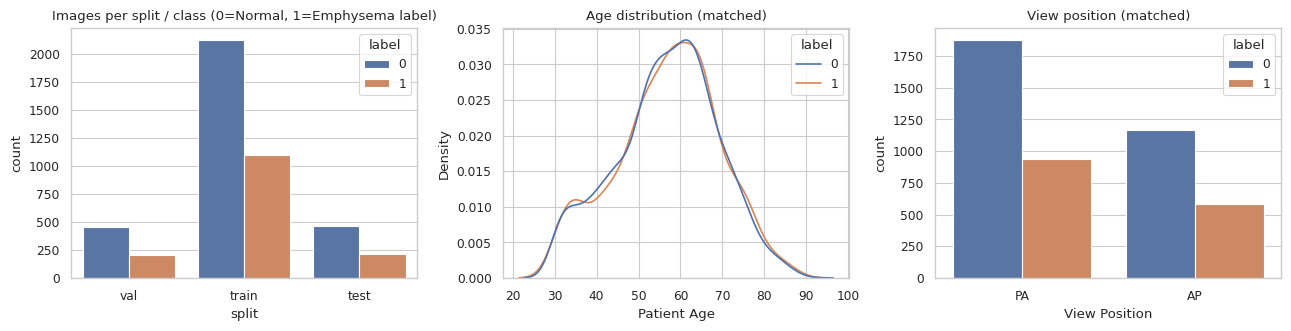

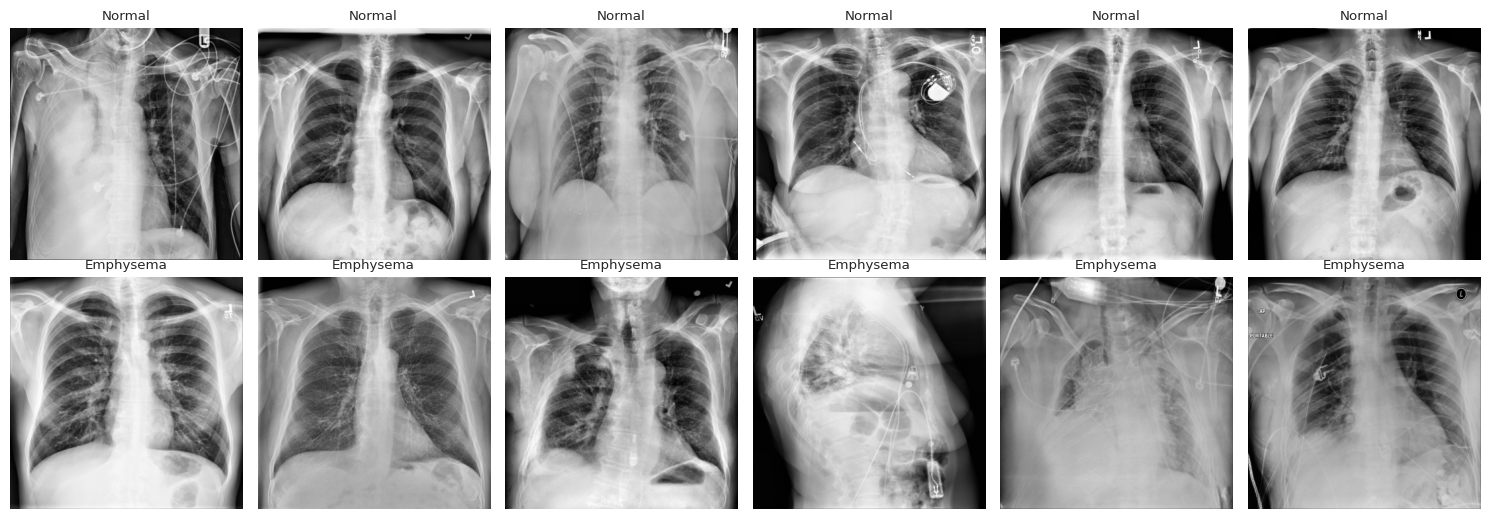

In [ ]:
# ===== 3. DATA AUDIT + PATIENT-LEVEL SPLIT + LEAKAGE CHECKS =====
import matplotlib; import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import StratifiedGroupKFold
sns.set_theme(style='whitegrid', context='paper')

# 3a. patient-level split (70/15/15). A patient is NEVER in more than one split.
sgkf = StratifiedGroupKFold(n_splits=20, shuffle=True, random_state=CFG['SEED'])
fold = np.zeros(len(meta), int)
for k, (_, te) in enumerate(sgkf.split(meta, meta.label, groups=meta['Patient ID'])): fold[te] = k
meta['split'] = np.where(fold < 3, 'test', np.where(fold < 6, 'val', 'train'))
pid = {s: set(meta.loc[meta.split == s, 'Patient ID']) for s in ['train', 'val', 'test']}
assert not (pid['train'] & pid['val']) and not (pid['train'] & pid['test']) and not (pid['val'] & pid['test']), 'patient leakage!'
print('Patient overlap between splits: 0  (OK)')

# 3b. near-duplicate audit across splits (Pearson correlation of 48x48 thumbnails)
th = np.stack([cv2.resize(x, (48, 48), interpolation=cv2.INTER_AREA) for x in X]).reshape(len(X), -1).astype(np.float32)
th = (th - th.mean(1, keepdims=True)); th /= (np.linalg.norm(th, axis=1, keepdims=True) + 1e-6)
tr_idx = np.where(meta.split == 'train')[0]; drop = []
for s in ['val', 'test']:
    ev = np.where(meta.split == s)[0]
    mx = (th[ev] @ th[tr_idx].T).max(1)
    flagged = ev[mx > 0.985]; drop += list(flagged)
    print(f'{s}: {len(flagged)} / {len(ev)} images are near-duplicates of a train image (corr > 0.985) -> removed')
keep = np.ones(len(meta), bool); keep[drop] = False
meta = meta[keep].reset_index(drop=True); X = X[keep]
meta.to_csv(OUT / 'tables' / 'final_dataset_manifest.csv', index=False)

# 3c. dataset tables + figures
tab = meta.groupby(['split', 'label']).agg(images=('label', 'size'), patients=('Patient ID', 'nunique'),
        age_mean=('Patient Age', 'mean'), male_frac=('Patient Gender', lambda g: (g == 'M').mean()),
        PA_frac=('View Position', lambda g: (g == 'PA').mean())).round(3)
tab.to_csv(OUT / 'tables' / 'dataset_summary.csv'); display(tab)
fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
sns.countplot(data=meta, x='split', hue='label', ax=ax[0]); ax[0].set_title('Images per split / class (0=Normal, 1=Emphysema label)')
sns.kdeplot(data=meta, x='Patient Age', hue='label', common_norm=False, ax=ax[1]); ax[1].set_title('Age distribution (matched)')
sns.countplot(data=meta, x='View Position', hue='label', ax=ax[2]); ax[2].set_title('View position (matched)')
plt.tight_layout(); plt.savefig(OUT / 'figures' / 'fig_dataset_overview.png', dpi=300); plt.show()
fig, ax = plt.subplots(2, 6, figsize=(15, 5.2)); rs = np.random.RandomState(0)
for r, lab in enumerate([0, 1]):
    for c, i in enumerate(rs.choice(np.where(meta.label == lab)[0], 6, replace=False)):
        ax[r, c].imshow(X[i], cmap='gray'); ax[r, c].axis('off'); ax[r, c].set_title(['Normal', 'Emphysema'][lab])
plt.tight_layout(); plt.savefig(OUT / 'figures' / 'fig_sample_images.png', dpi=300); plt.show()

In [ ]:
# ===== 4. GPU DATA + AUGMENTATION =====
import torch, torch.nn as nn, torch.nn.functional as F, torchvision as tv
dev = torch.device('cuda' if torch.cuda.is_available() else 'cpu'); AMP = dev.type == 'cuda'
print('Device:', dev, torch.cuda.get_device_name(0) if AMP else '')
S, IMG = CFG['IMG_STORE'], CFG['IMG_SIZE']
Xg = torch.from_numpy(X).to(dev)                                   # uint8, whole dataset lives on the GPU
yg = torch.tensor(meta.label.values, dtype=torch.float32, device=dev)
IDX = {s: torch.tensor(np.where(meta.split == s)[0], device=dev) for s in ['train', 'val', 'test']}
if CFG['TRAIN_SUBSET']: IDX['train'] = IDX['train'][torch.randperm(len(IDX['train']), device=dev)[:CFG['TRAIN_SUBSET']]]
MEAN, STD = 0.449, 0.226
def _norm(x): return ((x - MEAN) / STD).expand(-1, 3, -1, -1)

def prep_eval(xb):                       # center crop, no randomness
    o = (S - IMG) // 2
    return _norm(xb[:, o:o + IMG, o:o + IMG].float().div(255).unsqueeze(1))

def prep_train(xb):                      # random affine + intensity jitter + noise, all on GPU
    B = xb.shape[0]; x = xb.float().div(255).unsqueeze(1)
    r = lambda lo, hi: torch.rand(B, device=dev) * (hi - lo) + lo
    ang = r(-1, 1) * math.radians(7); s = (IMG / S) * r(0.92, 1.08)
    tx, ty = r(-0.05, 0.05), r(-0.05, 0.05)
    theta = torch.stack([torch.stack([s * torch.cos(ang), -s * torch.sin(ang), tx], 1),
                         torch.stack([s * torch.sin(ang),  s * torch.cos(ang), ty], 1)], 1)
    x = F.grid_sample(x, F.affine_grid(theta, (B, 1, IMG, IMG), align_corners=False), padding_mode='border', align_corners=False)
    x = ((x - 0.5) * r(0.85, 1.15).view(B, 1, 1, 1) + 0.5 + r(-0.08, 0.08).view(B, 1, 1, 1)).clamp(0, 1)
    x = (x + 0.01 * torch.randn_like(x)).clamp(0, 1)
    return _norm(x)                      # NOTE: no horizontal flip (heart side / anatomy matter)

Device: cuda Tesla T4


In [ ]:
# ===== 5. MODEL: pretrained backbone + attention blocks =====
# All attention blocks are written in residual form so the pretrained features are preserved at initialisation.

class SE(nn.Module):                      # Squeeze-and-Excitation (channel recalibration)
    def __init__(s, c, r=16):
        super().__init__(); s.fc = nn.Sequential(nn.Linear(c, c // r), nn.ReLU(True), nn.Linear(c // r, c), nn.Sigmoid())
    def forward(s, x): return x + x * s.fc(x.mean((2, 3)))[:, :, None, None]

class CBAM(nn.Module):                    # channel attention -> spatial attention
    def __init__(s, c, r=16, k=7):
        super().__init__()
        s.mlp = nn.Sequential(nn.Conv2d(c, c // r, 1, bias=False), nn.ReLU(True), nn.Conv2d(c // r, c, 1, bias=False))
        s.sp = nn.Conv2d(2, 1, k, padding=k // 2, bias=False)
    def forward(s, x):
        ca = torch.sigmoid(s.mlp(x.mean((2, 3), keepdim=True)) + s.mlp(x.amax((2, 3), keepdim=True)))
        y = x * ca
        sa = torch.sigmoid(s.sp(torch.cat([y.mean(1, keepdim=True), y.amax(1, keepdim=True)], 1)))
        return x + y * sa

class SelfAttn(nn.Module):                # standard non-local 2-D self-attention (position-blind), gamma-residual
    def __init__(s, c, r=8):
        super().__init__()
        s.q, s.k = nn.Conv2d(c, c // r, 1), nn.Conv2d(c, c // r, 1)
        s.v, s.o = nn.Conv2d(c, c // 2, 1), nn.Conv2d(c // 2, c, 1)
        s.gamma = nn.Parameter(torch.zeros(1))
    def forward(s, x):
        with torch.autocast(device_type=x.device.type, enabled=False):
            x = x.float(); B, C, H, W = x.shape
            q = s.q(x).flatten(2).transpose(1, 2); k = s.k(x).flatten(2); v = s.v(x).flatten(2).transpose(1, 2)
            a = torch.softmax((q @ k) / math.sqrt(q.shape[-1]), -1)
            o = (a @ v).transpose(1, 2).reshape(B, -1, H, W)
            return x + s.gamma * s.o(o)

class AxialMHA(nn.Module):                # multi-head attention along ONE axis with learned absolute position embedding
    def __init__(s, c, heads, axis, length, use_pos=True):
        super().__init__(); s.axis = axis
        s.pos = nn.Parameter(torch.zeros(1, length, c), requires_grad=use_pos)
        if use_pos: nn.init.trunc_normal_(s.pos, std=0.02)
        s.norm = nn.LayerNorm(c); s.attn = nn.MultiheadAttention(c, heads, batch_first=True)
    def forward(s, x):
        B, C, H, W = x.shape
        t = x.permute(0, 3, 2, 1).reshape(B * W, H, C) if s.axis == 'h' else x.permute(0, 2, 3, 1).reshape(B * H, W, C)
        t = s.norm(t + s.pos); o, _ = s.attn(t, t, t, need_weights=False)
        return o.reshape(B, W, H, C).permute(0, 3, 2, 1) if s.axis == 'h' else o.reshape(B, H, W, C).permute(0, 3, 1, 2)

class PADA(nn.Module):
    def __init__(s, c, hw, red=4, heads=8, use_pos=True):
        super().__init__(); cr = c // red
        s.reduce = nn.Sequential(nn.Conv2d(c, cr, 1, bias=False), nn.BatchNorm2d(cr), nn.ReLU(True))
        s.av, s.ah = AxialMHA(cr, heads, 'h', hw[0], use_pos), AxialMHA(cr, heads, 'w', hw[1], use_pos)
        s.gate = nn.Sequential(nn.Conv2d(2 * cr, cr, 1), nn.Sigmoid())
        s.expand = nn.Sequential(nn.Conv2d(cr, c, 1, bias=False), nn.BatchNorm2d(c))
        s.gamma = nn.Parameter(torch.zeros(1))
    def forward(s, x):
        z = s.reduce(x); a, b = s.av(z), s.ah(z); g = s.gate(torch.cat([a, b], 1))
        return x + s.gamma * s.expand(g * a + (1 - g) * b)

class Net(nn.Module):
    def __init__(s, backbone, blocks, drop=0.3, pretrained=True, img=320):
        super().__init__()
        # Dynamically load model from torchvision.models to circumvent missing get_model in older versions
        model_fn = getattr(tv.models, backbone)
        if pretrained:
            try:
                # Modern API
                weights_enum = getattr(tv.models, f"{backbone.upper()}_Weights", None)
                if weights_enum is not None:
                    m = model_fn(weights=weights_enum.DEFAULT)
                else:
                    m = model_fn(pretrained=True)
            except TypeError:
                # Older API
                m = model_fn(pretrained=True)
        else:
            m = model_fn(pretrained=False)

        if backbone.startswith('resnet'):
            s.feat = nn.Sequential(m.conv1, m.bn1, m.relu, m.maxpool, m.layer1, m.layer2, m.layer3, m.layer4)
        elif backbone.startswith('densenet'):
            s.feat = nn.Sequential(m.features, nn.ReLU(inplace=False))
        else:
            s.feat = m.features
        with torch.no_grad(): f = s.feat.eval()(torch.zeros(1, 3, img, img))
        c, hw = f.shape[1], f.shape[2:]; s.feat.train()
        mk = dict(se=lambda: SE(c), cbam=lambda: CBAM(c), sa=lambda: SelfAttn(c), pada=lambda: PADA(c, hw), padanp=lambda: PADA(c, hw, use_pos=False))
        s.attn = nn.Sequential(*[mk[b]() for b in blocks]) if blocks else nn.Identity()
        s.head = nn.Sequential(nn.Dropout(drop), nn.Linear(c, 512), nn.ReLU(True), nn.Dropout(drop), nn.Linear(512, 1))
    def forward(s, x):
        f = s.attn(s.feat(x)); return s.head(f.mean((2, 3)))

LADDER = [
    ('M0_baseline',      [],                        'ResNet-50 (baseline)'),
    ('M1_se',            ['se'],                    '+SE'),
    ('M2_cbam',          ['cbam'],                  '+CBAM'),
    ('M3_se_cbam',       ['se', 'cbam'],            '+SE+CBAM'),
    ('M4_se_cbam_sa',    ['se', 'cbam', 'sa'],      '+SE+CBAM+SA'),
    ('M5_se_cbam_pada',  ['se', 'cbam', 'pada'],    '+SE+CBAM+PADA (Proposed)'),
    ('M6_pada',          ['pada'],                  '+PADA only'),
    ('M7_cbam_pada',     ['cbam', 'pada'],          '+CBAM+PADA'),
]
EXTRA = [('M8_se_cbam_axial_nopos', ['se', 'cbam', 'padanp'], '+SE+CBAM+axial attention (no position embedding)')]
if CFG.get('RUN_EXTRA_ABLATIONS', False): LADDER += EXTRA
MAIN_KEYS = ['M0_baseline', 'M4_se_cbam_sa', 'M5_se_cbam_pada']
NAMES = {k: n for k, _, n in LADDER}; BLOCKS = {k: b for k, b, _ in LADDER}
bb = CFG['BACKBONE']; NAMES['M0_baseline'] = f"{bb.replace('resnet', 'ResNet-')} (baseline)"
_t = Net(bb, ['se', 'cbam', 'pada'], pretrained=False, img=IMG)
print('Feature-map size entering attention:', tuple(_t.feat.eval()(torch.zeros(1, 3, IMG, IMG)).shape[1:]), '| proposed params (M):', round(sum(p.numel() for p in _t.parameters()) / 1e6, 2)); del _t

Feature-map size entering attention: (2048, 10, 10) | proposed params (M): 30.35


In [ ]:
# ===== 6. METRICS, COMPLEXITY, TRAINING HARNESS =====
from sklearn.metrics import (roc_auc_score, average_precision_score, confusion_matrix, f1_score,
                             matthews_corrcoef, brier_score_loss, roc_curve)
from torch.utils.flop_counter import FlopCounterMode

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

def ece_score(p, y, bins=10):
    e, b = 0.0, np.linspace(0, 1, bins + 1)
    for lo, hi in zip(b[:-1], b[1:]):
        m = (p > lo) & (p <= hi)
        if m.any(): e += m.mean() * abs(p[m].mean() - y[m].mean())
    return float(e)

def youden_thr(p, y):
    fpr, tpr, th = roc_curve(y, p); return float(th[np.argmax(tpr - fpr)])

def compute_metrics(p, y, thr):
    pred = (p >= thr).astype(int); tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    sens, spec, prec = tp / max(tp + fn, 1), tn / max(tn + fp, 1), tp / max(tp + fp, 1)
    return dict(auc=float(roc_auc_score(y, p)), ap=float(average_precision_score(y, p)), acc=float((tp + tn) / len(y)),
                bal_acc=float((sens + spec) / 2), sensitivity=float(sens), specificity=float(spec), precision=float(prec),
                f1=float(f1_score(y, pred)), mcc=float(matthews_corrcoef(y, pred)), brier=float(brier_score_loss(y, p)),
                ece=ece_score(p, y), thr=float(thr), tn=int(tn), fp=int(fp), fn=int(fn), tp=int(tp))

@torch.no_grad()
def predict(model, idx, bs=64):
    model.eval(); out = []
    for i in range(0, len(idx), bs):
        with torch.autocast(dev.type, dtype=torch.float16, enabled=AMP):
            out.append(model(prep_eval(Xg[idx[i:i + bs]])).float().squeeze(1).cpu())
    lg = torch.cat(out); y = yg[idx].cpu()
    return torch.sigmoid(lg).numpy(), y.numpy(), F.binary_cross_entropy_with_logits(lg, y).item()

@torch.no_grad()
def complexity(model):
    model.eval(); x = torch.zeros(1, 3, IMG, IMG, device=dev)
    with FlopCounterMode(display=False) as fc: model(x)
    flops = fc.get_total_flops()                                  # counts multiply+add as 2 FLOPs
    lat = None
    if AMP:
        for _ in range(20): model(x)
        torch.cuda.synchronize(); t = time.time()
        for _ in range(100): model(x)
        torch.cuda.synchronize(); lat = (time.time() - t) * 10    # ms / image (batch 1, fp32)
    return dict(params_M=sum(p.numel() for p in model.parameters()) / 1e6, gflops=flops / 1e9, latency_ms=lat)

def run_experiment(key, blocks, seed, backbone, force=False):
    rd = OUT / 'models' / backbone / f'{key}_s{seed}'; rd.mkdir(parents=True, exist_ok=True)
    if (rd / 'metrics.json').exists() and not force:
        print(f'[skip] {key} seed {seed} (already done)'); return json.load(open(rd / 'metrics.json'))
    set_seed(seed); torch.backends.cudnn.benchmark = True
    model = Net(backbone, blocks, CFG['DROPOUT'], img=IMG).to(dev)
    new_p = [p for n, p in model.named_parameters() if not n.startswith('feat.')]
    old_p = [p for n, p in model.named_parameters() if n.startswith('feat.')]
    opt = torch.optim.AdamW([dict(params=old_p, lr=CFG['LR_BACKBONE']), dict(params=new_p, lr=CFG['LR_NEW'])], weight_decay=CFG['WD'])
    ntr = len(IDX['train']); spe = ntr // CFG['BATCH']; total, warm = CFG['EPOCHS'] * spe, CFG['WARMUP_EPOCHS'] * spe
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda t: (t + 1) / warm if t < warm else max(0.01, 0.5 * (1 + math.cos(math.pi * (t - warm) / max(1, total - warm)))))
    scaler = torch.amp.GradScaler(dev.type, enabled=AMP)
    ytr = yg[IDX['train']]; pw = ((1 - ytr.mean()) / ytr.mean()).detach()
    hist = dict(train_loss=[], train_acc=[], val_loss=[], val_acc=[], val_auc=[], lr=[]); best = dict(auc=-1, loss=9, epoch=-1); ep0 = 0
    if (rd / 'last.pt').exists():                                  # resume after a Colab disconnect
        ck = torch.load(rd / 'last.pt', map_location=dev); model.load_state_dict(ck['model']); opt.load_state_dict(ck['opt'])
        sched.load_state_dict(ck['sched']); scaler.load_state_dict(ck['scaler']); hist, best, ep0 = ck['hist'], ck['best'], ck['epoch']
        print(f'[resume] {key} seed {seed} from epoch {ep0}')
    t0 = time.time(); ls = CFG['LABEL_SMOOTH']
    for ep in range(ep0, CFG['EPOCHS']):                           # fixed number of epochs, NO early stopping
        model.train(); perm = IDX['train'][torch.randperm(ntr, device=dev)]; tl = tc = n = 0
        for i in range(0, ntr - CFG['BATCH'] + 1, CFG['BATCH']):
            b = perm[i:i + CFG['BATCH']]; y = yg[b]; ysm = y * (1 - 2 * ls) + ls
            with torch.autocast(dev.type, dtype=torch.float16, enabled=AMP):
                lg = model(prep_train(Xg[b])).float().squeeze(1)
            loss = F.binary_cross_entropy_with_logits(lg, ysm, pos_weight=pw)
            if not torch.isfinite(loss): continue                                  # safety: never step on a NaN batch
            opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), CFG['GRAD_CLIP']); scaler.step(opt); scaler.update(); sched.step()
            tl += loss.item() * len(b); tc += ((lg > 0).float() == y).sum().item(); n += len(b)
        pv, yv, vl = predict(model, IDX['val']); assert np.isfinite(pv).all(), 'NaN in val predictions - weights diverged'
        vauc = roc_auc_score(yv, pv)
        hist['train_loss'].append(tl / n); hist['train_acc'].append(tc / n); hist['val_loss'].append(vl)
        hist['val_acc'].append(float(((pv > 0.5) == yv).mean())); hist['val_auc'].append(float(vauc)); hist['lr'].append(opt.param_groups[0]['lr'])
        if vauc > best['auc'] or (vauc == best['auc'] and vl < best['loss']):
            best = dict(auc=float(vauc), loss=vl, epoch=ep + 1); torch.save(model.state_dict(), rd / 'best.pt')
        print(f"{key:18s} s{seed} ep {ep+1:02d}/{CFG['EPOCHS']} | tr_loss {hist['train_loss'][-1]:.3f} tr_acc {hist['train_acc'][-1]:.3f} | "
              f"val_loss {vl:.3f} val_acc {hist['val_acc'][-1]:.3f} val_auc {vauc:.4f} | best {best['auc']:.4f}@{best['epoch']} | {(time.time()-t0)/60:.1f} min")
        if (ep + 1) % 5 == 0 and ep + 1 < CFG['EPOCHS']:
            torch.save(dict(model=model.state_dict(), opt=opt.state_dict(), sched=sched.state_dict(), scaler=scaler.state_dict(),
                            hist=hist, best=best, epoch=ep + 1), rd / 'last.pt')
    # --- final evaluation ---
    pv_l, yv, _ = predict(model, IDX['val']); pt_l, yt, _ = predict(model, IDX['test'])      # last-epoch weights (no selection)
    thr_l = youden_thr(pv_l, yv); res_last = compute_metrics(pt_l, yt, thr_l)
    model.load_state_dict(torch.load(rd / 'best.pt', map_location=dev))                      # best-val-AUC weights
    pv, yv, _ = predict(model, IDX['val']); pt, yt, tloss = predict(model, IDX['test'])
    thr = youden_thr(pv, yv)                                                                  # threshold from VAL only
    res = dict(key=key, seed=seed, backbone=backbone, blocks=blocks, best_epoch=best['epoch'], test=compute_metrics(pt, yt, thr),
               val=compute_metrics(pv, yv, thr), test_last_epoch=res_last, test_loss=tloss, train_minutes=(time.time() - t0) / 60, **complexity(model))
    json.dump(res, open(rd / 'metrics.json', 'w'), indent=2); json.dump(hist, open(rd / 'history.json', 'w'))
    np.savez(rd / 'preds.npz', val_p=pv, val_y=yv, test_p=pt, test_y=yt, test_idx=IDX['test'].cpu().numpy())
    (rd / 'last.pt').unlink(missing_ok=True)
    print(f"==> {key} s{seed}: TEST AUC {res['test']['auc']:.4f} | Acc {res['test']['acc']:.4f} | F1 {res['test']['f1']:.4f}\n")
    del model, opt; torch.cuda.empty_cache(); return res

In [ ]:
# ===== 7. RUN ALL EXPERIMENTS (resumable: finished runs are skipped, interrupted runs resume) =====
# Order: full ablation ladder (seed 42) first, then extra seeds for baseline / +SA / proposed.
jobs = [(k, BLOCKS[k], s, bb) for k in BLOCKS for s in CFG['ABLATION_SEEDS']]
jobs += [(k, BLOCKS[k], s, bb) for k in MAIN_KEYS for s in CFG['MAIN_SEEDS'] if s not in CFG['ABLATION_SEEDS']]
if CFG['RUN_EXTERNAL']:      # optional reference baselines used by many CXR papers (CheXNet = DenseNet-121)
    for ext in ['densenet121', 'efficientnet_b0']:
        jobs += [(f'EXT_{ext}', [], s, ext) for s in CFG['ABLATION_SEEDS']]
print(f'{len(jobs)} runs x {CFG["EPOCHS"]} epochs')
for key, blocks, seed, backbone in jobs:
    run_experiment(key, blocks, seed, backbone)

14 runs x 50 epochs
[skip] M0_baseline seed 42 (already done)
[skip] M1_se seed 42 (already done)
[skip] M2_cbam seed 42 (already done)
[skip] M3_se_cbam seed 42 (already done)
[skip] M4_se_cbam_sa seed 42 (already done)
[skip] M5_se_cbam_pada seed 42 (already done)
[skip] M6_pada seed 42 (already done)
[skip] M7_cbam_pada seed 42 (already done)
[skip] M0_baseline seed 1337 (already done)
[skip] M0_baseline seed 2024 (already done)
[skip] M4_se_cbam_sa seed 1337 (already done)
[skip] M4_se_cbam_sa seed 2024 (already done)
[skip] M5_se_cbam_pada seed 1337 (already done)
[skip] M5_se_cbam_pada seed 2024 (already done)


In [ ]:
# ===== 8. COLLECT RESULTS -> TABLES =====
def load_all():
    rows = []
    for f in glob.glob(str(OUT / 'models' / '*' / '*' / 'metrics.json')):
        r = json.load(open(f)); t = r['test']
        rows.append(dict(backbone=r['backbone'], key=r['key'], model=NAMES.get(r['key'], r['key']), seed=r['seed'], best_epoch=r['best_epoch'],
                         params_M=r['params_M'], GFLOPs=r['gflops'], latency_ms=r['latency_ms'], train_min=r['train_minutes'],
                         AUC=t['auc'], AP=t['ap'], Acc=t['acc'], BalAcc=t['bal_acc'], Sens=t['sensitivity'], Spec=t['specificity'],
                         Prec=t['precision'], F1=t['f1'], MCC=t['mcc'], Brier=t['brier'], ECE=t['ece'], AUC_lastEpoch=r['test_last_epoch']['auc']))
    return pd.DataFrame(rows)
R = load_all(); order = {k: i for i, k in enumerate(list(NAMES))}
R['o'] = R.key.map(order); R = R.sort_values(['backbone', 'o', 'seed']).drop(columns='o')
R.to_csv(OUT / 'tables' / 'all_runs.csv', index=False)
M = ['AUC', 'AP', 'Acc', 'BalAcc', 'Sens', 'Spec', 'F1', 'MCC']
main = R[(R.backbone == bb) & (~R.key.str.startswith('EXT'))]

# Table 1: ablation ladder, seed 42 (single run each)
t1 = main[main.seed == CFG['SEED']].set_index('model')[['params_M', 'GFLOPs', 'latency_ms'] + M + ['Brier', 'ECE', 'best_epoch']]
t1.round(4).to_csv(OUT / 'tables' / 'table1_ablation_seed42.csv'); t1.round(4).to_latex(OUT / 'tables' / 'table1_ablation_seed42.tex')
display(t1.round(4))

# Table 2: mean +- std over seeds for the main models
g = main[main.key.isin(MAIN_KEYS)].groupby('key')
t2 = pd.DataFrame({NAMES[k]: {m: f"{d[m].mean():.4f} ± {d[m].std(ddof=0):.4f}" for m in M} | {'n_seeds': len(d)} for k, d in g}).T
t2.to_csv(OUT / 'tables' / 'table2_main_models_mean_std.csv'); t2.to_latex(OUT / 'tables' / 'table2_main_models_mean_std.tex'); display(t2)

,params_M,GFLOPs,latency_ms,AUC,AP,Acc,BalAcc,Sens,Spec,F1,MCC,Brier,ECE,best_epoch
model,,,,,,,,,,,,,,
ResNet-50 (baseline),24.5576,16.6843,10.0408,0.8318,0.7347,0.7522,0.7546,0.7615,0.7478,0.6640,0.4826,0.1964,0.1468,22
+SE,25.0841,16.6853,10.0840,0.8241,0.7250,0.7065,0.7318,0.8028,0.6609,0.6375,0.4332,0.1567,0.0849,6
+CBAM,25.0820,16.6864,10.0461,0.8145,0.6574,0.6917,0.7294,0.8349,0.6239,0.6353,0.4290,0.1894,0.1368,23
+SE+CBAM,25.6085,16.6875,10.1344,0.8431,0.7414,0.7257,0.7520,0.8257,0.6783,0.6593,0.4710,0.1572,0.0869,11
+SE+CBAM+SA,30.8549,17.7616,11.1098,0.8269,0.6711,0.7389,0.7606,0.8211,0.7000,0.6692,0.4878,0.1671,0.1044,11
+SE+CBAM+PADA (Proposed),30.3491,17.2117,11.3256,0.8439,0.7403,0.7684,0.7654,0.7569,0.7739,0.6776,0.5068,0.1727,0.1663,7
+PADA only,29.2982,17.2086,11.1962,0.8388,0.7183,0.7375,0.7607,0.8257,0.6957,0.6691,0.4878,0.2092,0.1880,17
+CBAM+PADA,29.8226,17.2107,11.2637,0.8510,0.7487,0.7891,0.7722,0.7248,0.8196,0.6885,0.5312,0.1779,0.1408,11


,AUC,AP,Acc,BalAcc,Sens,Spec,F1,MCC,n_seeds
ResNet-50 (baseline),0.8342 ± 0.0061,0.7383 ± 0.0082,0.7443 ± 0.0091,0.7525 ± 0.0089,0.7752 ± 0.0163,0.7297 ± 0.0136,0.6610 ± 0.0102,0.4762 ± 0.0170,3
+SE+CBAM+SA,0.8486 ± 0.0164,0.7378 ± 0.0472,0.7566 ± 0.0158,0.7696 ± 0.0064,0.8058 ± 0.0284,0.7333 ± 0.0356,0.6807 ± 0.0084,0.5085 ± 0.0154,3
+SE+CBAM+PADA (Proposed),0.8501 ± 0.0050,0.7500 ± 0.0125,0.7606 ± 0.0155,0.7684 ± 0.0089,0.7905 ± 0.0249,0.7464 ± 0.0316,0.6800 ± 0.0110,0.5080 ± 0.0187,3


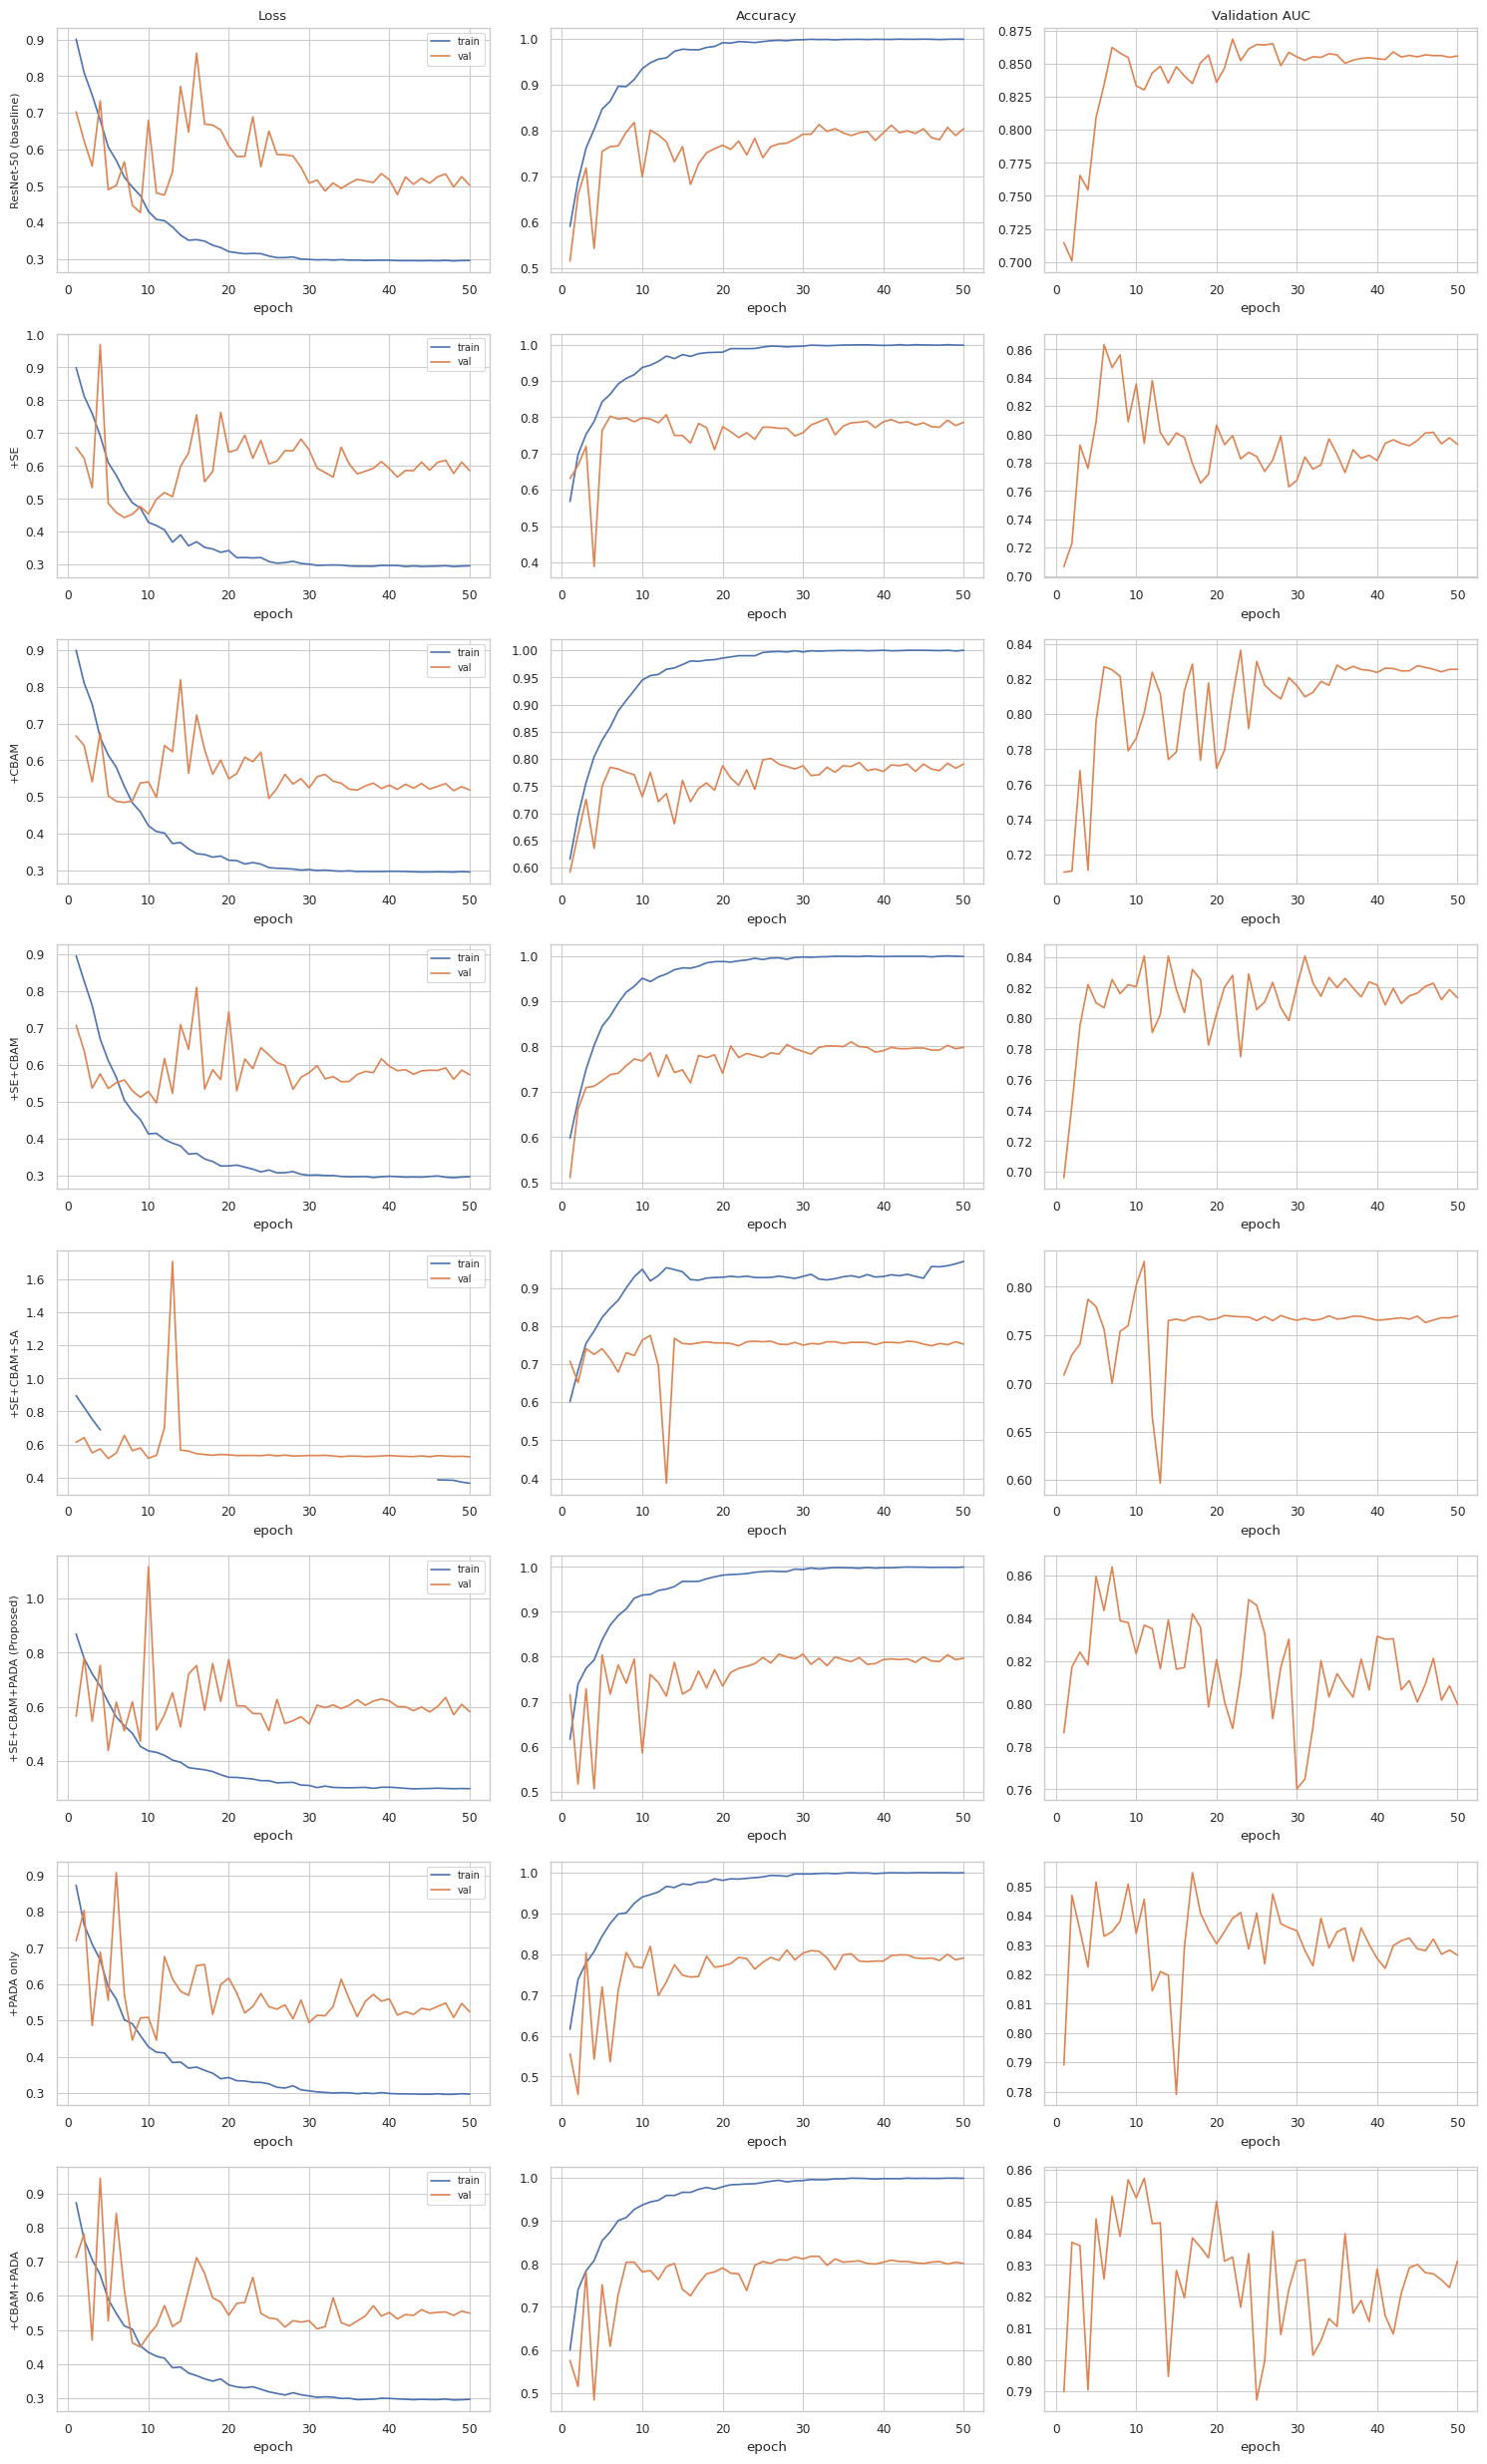

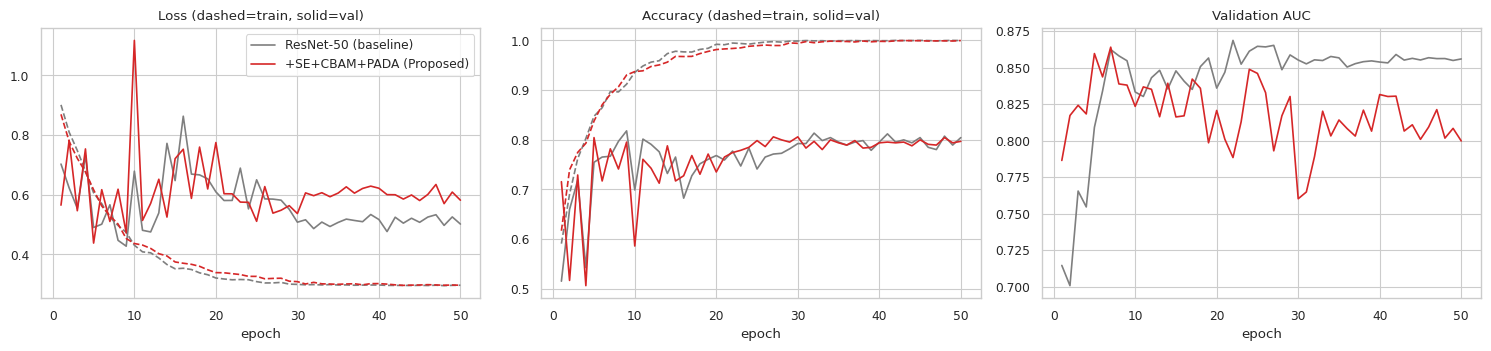

,model,best_epoch,final_train_acc,final_val_acc,acc_gap,final_train_loss,final_val_loss,min_val_loss,epoch_min_val_loss,val_auc_best,val_auc_final
0,ResNet-50 (baseline),22,0.9997,0.8042,0.1955,0.2968,0.5017,0.4276,9,0.8686,0.8559
1,+SE,6,0.9988,0.7861,0.2126,0.2966,0.5857,0.4432,7,0.8633,0.7930
2,+CBAM,23,1.0000,0.7907,0.2093,0.2955,0.5190,0.4851,7,0.8365,0.8257
3,+SE+CBAM,11,0.9988,0.7982,0.2006,0.2970,0.5729,0.4965,11,0.8407,0.8134
4,+SE+CBAM+SA,11,0.9703,0.7530,0.2173,0.3653,0.5256,0.5152,5,0.8263,0.7699
5,+SE+CBAM+PADA (Proposed),7,0.9997,0.7967,0.2030,0.2968,0.5817,0.4380,5,0.8640,0.7998
6,+PADA only,17,0.9997,0.7907,0.2090,0.2968,0.5240,0.4459,11,0.8547,0.8266
7,+CBAM+PADA,11,0.9994,0.8012,0.1982,0.2974,0.5492,0.4505,9,0.8574,0.8313


In [ ]:
# ===== 9. TRAINING CURVES (accuracy / loss / AUC) =====
def H(key, seed=CFG['SEED']): return json.load(open(OUT / 'models' / bb / f'{key}_s{seed}' / 'history.json'))
keys = [k for k in NAMES if (OUT / 'models' / bb / f'{k}_s{CFG["SEED"]}' / 'history.json').exists() and not k.startswith('EXT')]

def curves(klist, fname):
    fig, ax = plt.subplots(len(klist), 3, figsize=(15, 3.1 * len(klist)), squeeze=False)
    for r, k in enumerate(klist):
        h = H(k); e = np.arange(1, len(h['val_auc']) + 1)
        ax[r, 0].plot(e, h['train_loss'], label='train'); ax[r, 0].plot(e, h['val_loss'], label='val'); ax[r, 0].set_ylabel(NAMES[k], fontsize=8); ax[r, 0].set_title('Loss' if r == 0 else '')
        ax[r, 1].plot(e, h['train_acc'], label='train'); ax[r, 1].plot(e, h['val_acc'], label='val'); ax[r, 1].set_title('Accuracy' if r == 0 else '')
        ax[r, 2].plot(e, h['val_auc'], c='C1'); ax[r, 2].set_title('Validation AUC' if r == 0 else '')
        for a in ax[r]: a.set_xlabel('epoch')
        ax[r, 0].legend(fontsize=7)
    plt.tight_layout(); plt.savefig(OUT / 'figures' / fname, dpi=300); plt.savefig(OUT / 'figures' / fname.replace('.png', '.pdf')); plt.show()
curves(keys, 'fig_training_curves_all_models.png')
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
for k, c in [('M0_baseline', 'tab:gray'), ('M5_se_cbam_pada', 'tab:red')]:
    if k not in keys: continue
    h = H(k); e = np.arange(1, len(h['val_auc']) + 1)
    ax[0].plot(e, h['train_loss'], c=c, ls='--'); ax[0].plot(e, h['val_loss'], c=c, label=NAMES[k])
    ax[1].plot(e, h['train_acc'], c=c, ls='--'); ax[1].plot(e, h['val_acc'], c=c, label=NAMES[k]); ax[2].plot(e, h['val_auc'], c=c, label=NAMES[k])
for a, t in zip(ax, ['Loss (dashed=train, solid=val)', 'Accuracy (dashed=train, solid=val)', 'Validation AUC']): a.set_title(t); a.set_xlabel('epoch')
ax[0].legend(); plt.tight_layout(); plt.savefig(OUT / 'figures' / 'fig_curves_baseline_vs_proposed.png', dpi=300); plt.show()

# overfitting report
rows = []
for k in keys:
    h = H(k); b = int(np.argmax(h['val_auc']))
    rows.append(dict(model=NAMES[k], best_epoch=b + 1, final_train_acc=h['train_acc'][-1], final_val_acc=h['val_acc'][-1],
                     acc_gap=h['train_acc'][-1] - h['val_acc'][-1], final_train_loss=h['train_loss'][-1], final_val_loss=h['val_loss'][-1],
                     min_val_loss=min(h['val_loss']), epoch_min_val_loss=int(np.argmin(h['val_loss'])) + 1,
                     val_auc_best=max(h['val_auc']), val_auc_final=h['val_auc'][-1]))
OV = pd.DataFrame(rows).round(4); OV.to_csv(OUT / 'tables' / 'overfitting_report.csv', index=False); display(OV)

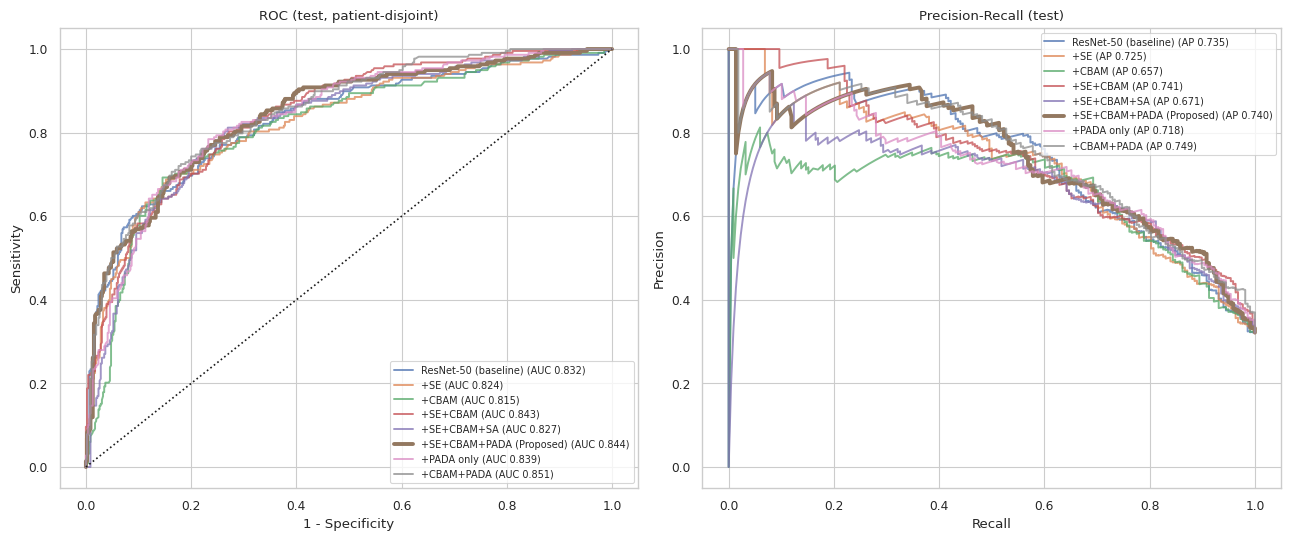

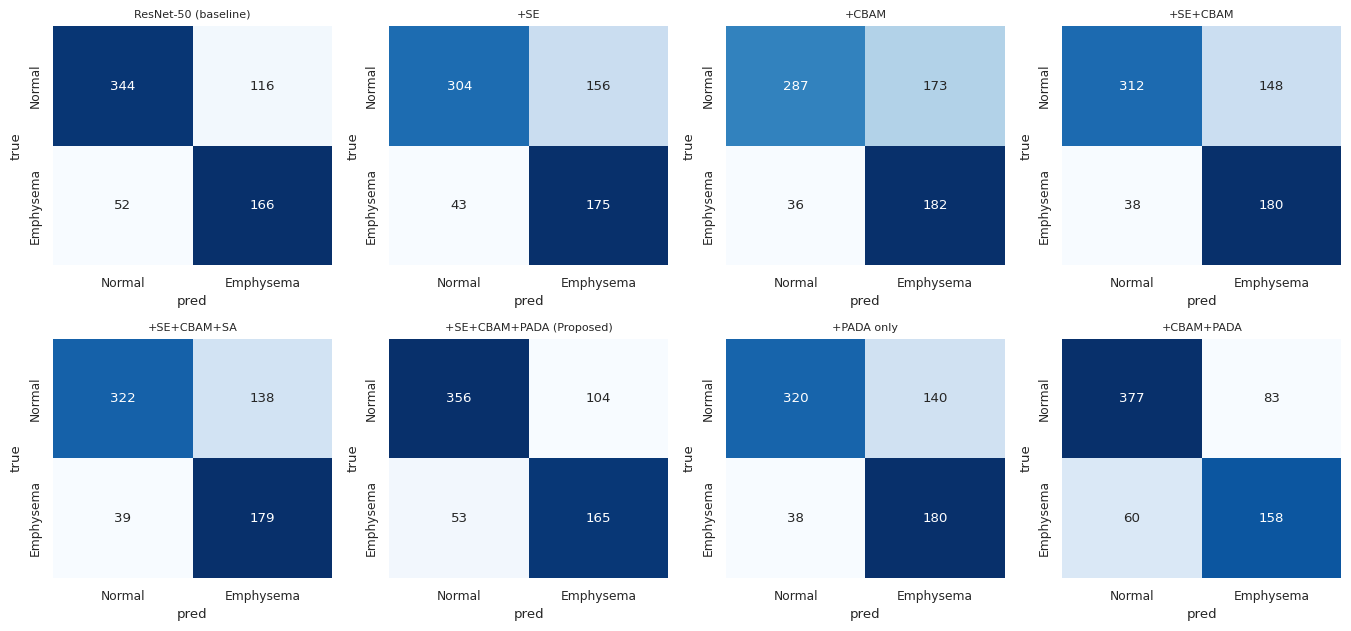

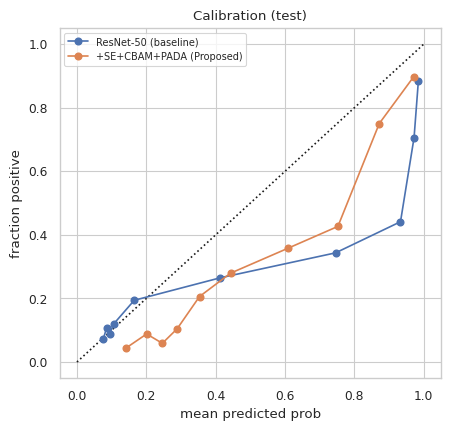

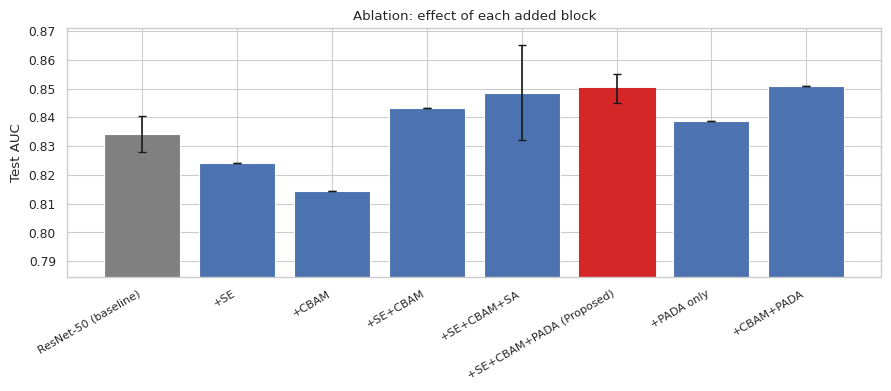

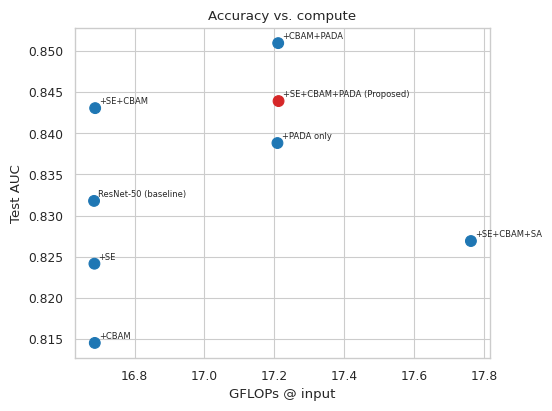

In [ ]:
# ===== 10. ROC / PR / CONFUSION / CALIBRATION / ABLATION BARS / EFFICIENCY =====
from sklearn.metrics import precision_recall_curve
def P(key, seed=CFG['SEED']): return np.load(OUT / 'models' / bb / f'{key}_s{seed}' / 'preds.npz')
def THR(key, seed=CFG['SEED']): return json.load(open(OUT / 'models' / bb / f'{key}_s{seed}' / 'metrics.json'))['test']['thr']
fig, ax = plt.subplots(1, 2, figsize=(13, 5.5))
for k in keys:
    d = P(k); f, t, _ = roc_curve(d['test_y'], d['test_p']); pr, rc, _ = precision_recall_curve(d['test_y'], d['test_p'])
    lw, al = (2.8, 1) if k == 'M5_se_cbam_pada' else (1.4, .75)
    ax[0].plot(f, t, lw=lw, alpha=al, label=f"{NAMES[k]} (AUC {roc_auc_score(d['test_y'], d['test_p']):.3f})")
    ax[1].plot(rc, pr, lw=lw, alpha=al, label=f"{NAMES[k]} (AP {average_precision_score(d['test_y'], d['test_p']):.3f})")
ax[0].plot([0, 1], [0, 1], 'k:'); ax[0].set(xlabel='1 - Specificity', ylabel='Sensitivity', title='ROC (test, patient-disjoint)'); ax[1].set(xlabel='Recall', ylabel='Precision', title='Precision-Recall (test)')
ax[0].legend(fontsize=7, loc='lower right'); ax[1].legend(fontsize=7, loc='upper right')
plt.tight_layout(); plt.savefig(OUT / 'figures' / 'fig_roc_pr_all_models.png', dpi=300); plt.savefig(OUT / 'figures' / 'fig_roc_pr_all_models.pdf'); plt.show()

nc = 4; nr = math.ceil(len(keys) / nc); fig, ax = plt.subplots(nr, nc, figsize=(3.4 * nc, 3.2 * nr)); ax = np.atleast_2d(ax)
for a in ax.ravel(): a.axis('off')
for a, k in zip(ax.ravel(), keys):
    d = P(k); cm = confusion_matrix(d['test_y'], (d['test_p'] >= THR(k)).astype(int)); a.axis('on')
    sns.heatmap(cm / cm.sum(1, keepdims=True), annot=cm, fmt='d', cmap='Blues', cbar=False, ax=a, xticklabels=['Normal', 'Emphysema'], yticklabels=['Normal', 'Emphysema'])
    a.set_title(NAMES[k], fontsize=8); a.set_xlabel('pred'); a.set_ylabel('true')
plt.tight_layout(); plt.savefig(OUT / 'figures' / 'fig_confusion_matrices.png', dpi=300); plt.show()

from sklearn.calibration import calibration_curve
plt.figure(figsize=(4.6, 4.4)); plt.plot([0, 1], [0, 1], 'k:')
for k in ['M0_baseline', 'M5_se_cbam_pada']:
    if k in keys: d = P(k); fp_, mp_ = calibration_curve(d['test_y'], d['test_p'], n_bins=10, strategy='quantile'); plt.plot(mp_, fp_, 'o-', label=NAMES[k])
plt.xlabel('mean predicted prob'); plt.ylabel('fraction positive'); plt.title('Calibration (test)'); plt.legend(fontsize=7); plt.tight_layout()
plt.savefig(OUT / 'figures' / 'fig_calibration.png', dpi=300); plt.show()

# ablation bars (mean over seeds where available, error bars = std)
a = main.groupby('model', sort=False).agg(AUC=('AUC', 'mean'), sd=('AUC', lambda v: v.std(ddof=0)), F1=('F1', 'mean')).reindex([NAMES[k] for k in keys])
plt.figure(figsize=(9, 4)); plt.bar(range(len(a)), a.AUC, yerr=a.sd, color=['gray'] + ['C0'] * (len(a) - 1), capsize=3)
for i, k in enumerate(keys):
    if k == 'M5_se_cbam_pada': plt.gca().patches[i].set_color('tab:red')
plt.xticks(range(len(a)), a.index, rotation=30, ha='right', fontsize=8); lo = max(0.5, a.AUC.min() - 0.03); plt.ylim(lo, min(1, a.AUC.max() + 0.02)); plt.ylabel('Test AUC')
plt.title('Ablation: effect of each added block'); plt.tight_layout(); plt.savefig(OUT / 'figures' / 'fig_ablation_auc.png', dpi=300); plt.show()

plt.figure(figsize=(5.6, 4.2)); e = main[main.seed == CFG['SEED']]
plt.scatter(e.GFLOPs, e.AUC, c=['tab:red' if k == 'M5_se_cbam_pada' else 'tab:blue' for k in e.key], s=60)
for _, r in e.iterrows(): plt.annotate(r.model, (r.GFLOPs, r.AUC), fontsize=6, xytext=(3, 3), textcoords='offset points')
plt.xlabel('GFLOPs @ input'); plt.ylabel('Test AUC'); plt.title('Accuracy vs. compute'); plt.tight_layout(); plt.savefig(OUT / 'figures' / 'fig_auc_vs_flops.png', dpi=300); plt.show()

In [ ]:
# ===== 11. STATISTICAL TESTS (paired, on the same test patients) =====
from scipy.stats import chi2
def paired_bootstrap(p0, p1, y, n=2000, seed=0):
    rs = np.random.RandomState(seed); d = []
    for _ in range(n):
        i = rs.randint(0, len(y), len(y))
        if y[i].min() == y[i].max(): continue
        d.append(roc_auc_score(y[i], p1[i]) - roc_auc_score(y[i], p0[i]))
    d = np.array(d); return d.mean(), np.percentile(d, 2.5), np.percentile(d, 97.5), float((d <= 0).mean())
def mcnemar(p0, p1, y, t0, t1):
    c0, c1 = (p0 >= t0) == y, (p1 >= t1) == y; b, c = int((c0 & ~c1).sum()), int((~c0 & c1).sum())
    return 1.0 if b + c == 0 else float(1 - chi2.cdf((abs(b - c) - 1) ** 2 / (b + c), 1))
rows = []; d0 = P('M0_baseline')
for k in keys[1:]:
    d1 = P(k); m, lo, hi, p = paired_bootstrap(d0['test_p'], d1['test_p'], d0['test_y'])
    rows.append(dict(model=NAMES[k], dAUC_vs_baseline=m, CI95_low=lo, CI95_high=hi, boot_p_one_sided=p,
                     mcnemar_p=mcnemar(d0['test_p'], d1['test_p'], d0['test_y'], THR('M0_baseline'), THR(k))))
SIG = pd.DataFrame(rows).round(4); SIG.to_csv(OUT / 'tables' / 'significance_vs_baseline.csv', index=False); display(SIG)
if 'M4_se_cbam_sa' in keys and 'M5_se_cbam_pada' in keys:
    d4, d5 = P('M4_se_cbam_sa'), P('M5_se_cbam_pada'); print('PADA vs plain self-attention (M5 vs M4): dAUC %.4f  CI [%.4f, %.4f]  p=%.4f' % paired_bootstrap(d4['test_p'], d5['test_p'], d4['test_y']))

,model,dAUC_vs_baseline,CI95_low,CI95_high,boot_p_one_sided,mcnemar_p
0,+SE,-0.0074,-0.0314,0.0173,0.7145,0.0068
1,+CBAM,-0.0169,-0.0391,0.0061,0.9245,0.0002
2,+SE+CBAM,0.0110,-0.0133,0.0345,0.1930,0.1299
3,+SE+CBAM+SA,-0.0050,-0.0309,0.0214,0.6435,0.4595
4,+SE+CBAM+PADA (Proposed),0.0120,-0.0162,0.0400,0.1890,0.3552
5,+PADA only,0.0071,-0.0183,0.0351,0.3185,0.4152
6,+CBAM+PADA,0.0189,-0.0068,0.0444,0.0775,0.0305


PADA vs plain self-attention (M5 vs M4): dAUC 0.0169  CI [-0.0134, 0.0481]  p=0.1450


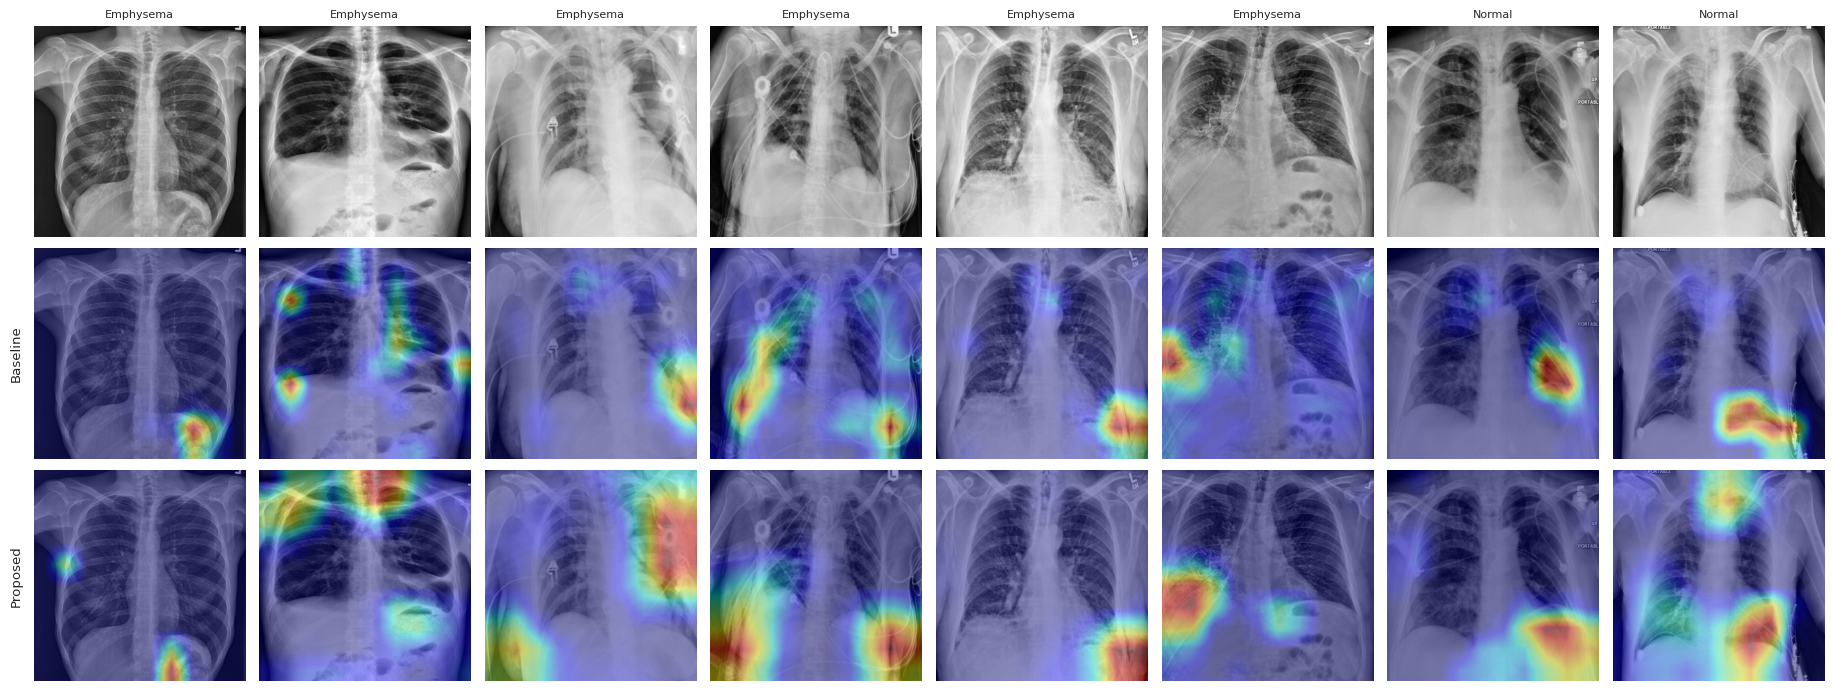

In [ ]:
# ===== 12. GRAD-CAM: baseline vs proposed =====
def gradcam(model, x):
    model.eval(); model.zero_grad(); f = model.attn(model.feat(x)); f.retain_grad()
    model.head(f.mean((2, 3))).sum().backward()
    cam = F.relu((f.grad.mean((2, 3), keepdim=True) * f).sum(1, keepdim=True))
    cam = F.interpolate(cam, size=(IMG, IMG), mode='bilinear', align_corners=False)[:, 0].detach()
    return (cam / (cam.amax((1, 2), keepdim=True) + 1e-8)).cpu().numpy()

def load_model(key):
    m = Net(bb, BLOCKS[key], CFG['DROPOUT'], pretrained=False, img=IMG).to(dev)
    m.load_state_dict(torch.load(OUT / 'models' / bb / f'{key}_s{CFG["SEED"]}' / 'best.pt', map_location=dev)); return m

if 'M5_se_cbam_pada' in keys:
    d5 = P('M5_se_cbam_pada'); ti = d5['test_idx']; yt = d5['test_y']
    GRADCAM_RANDOM = True      # True: seeded random sample (representative); False: most confident predictions
    if GRADCAM_RANDOM:
        rs = np.random.RandomState(0); tp = rs.choice(ti[yt == 1], 6, replace=False); tn = rs.choice(ti[yt == 0], 2, replace=False)
    else:
        tp = ti[np.argsort(-(d5['test_p'] * (yt == 1)))[:6]]; tn = ti[np.argsort(d5['test_p'] + 9 * (yt == 1))[:2]]
    sel = list(tp) + list(tn)
    models = {k: load_model(k) for k in ['M0_baseline', 'M5_se_cbam_pada']}
    fig, ax = plt.subplots(3, len(sel), figsize=(2.3 * len(sel), 7))
    for j, i in enumerate(sel):
        x = prep_eval(Xg[torch.tensor([i], device=dev)]); img = x[0, 0].cpu().numpy()
        ax[0, j].imshow(img, cmap='gray'); ax[0, j].set_title(['Normal', 'Emphysema'][int(meta.label[i])], fontsize=8)
        for r, k in enumerate(models, 1):
            ax[r, j].imshow(img, cmap='gray'); ax[r, j].imshow(gradcam(models[k], x)[0], cmap='jet', alpha=.4)
        for r in range(3): ax[r, j].axis('off')
    ax[1, 0].text(-0.05, .5, 'Baseline', transform=ax[1, 0].transAxes, rotation=90, ha='right', va='center'); ax[2, 0].text(-0.05, .5, 'Proposed', transform=ax[2, 0].transAxes, rotation=90, ha='right', va='center')
    plt.tight_layout(); plt.savefig(OUT / 'gradcam' / 'fig_gradcam_baseline_vs_proposed.png', dpi=300); plt.show()
    del models; torch.cuda.empty_cache()

In [ ]:
# ===== 12b. REVIEW-REQUESTED ANALYSES (confounding, subgroups, patient-clustered statistics) =====
# (1) co-occurring labels among emphysema-labelled images, (2) PA/AP and sex subgroup AUC, (3) patient-clustered bootstrap.
# Needs: the saved preds.npz files of the finished runs, the manifest, and Data_Entry_2017.csv (small; downloaded via the Kaggle API).
import os, zipfile
from pathlib import Path
import pandas as pd
import numpy as np
from google.colab import userdata
from kaggle.api.kaggle_api_extended import KaggleApi

os.environ['KAGGLE_USERNAME'] = userdata.get(CFG['KAGGLE_USER_SECRET'])
os.environ['KAGGLE_KEY']      = userdata.get(CFG['KAGGLE_KEY_SECRET'])

api = KaggleApi(); api.authenticate()
RAW2 = Path('/content/nih_meta'); RAW2.mkdir(exist_ok=True)
api.dataset_download_file('nih-chest-xrays/data', 'Data_Entry_2017.csv', path=str(RAW2))
zz = RAW2 / 'Data_Entry_2017.csv.zip'
if zz.exists(): zipfile.ZipFile(zz).extractall(RAW2); zz.unlink()
de = pd.read_csv(RAW2 / 'Data_Entry_2017.csv')[['Image Index', 'Finding Labels']]
mm = meta.merge(de, on='Image Index', how='left'); assert mm['Finding Labels'].notna().all()
pos = mm[mm.label == 1]
co = pos['Finding Labels'].str.split('|').explode(); co = co[co != 'Emphysema'].value_counts()
co_tab = pd.DataFrame({'images': co, 'percent_of_emphysema_images': (100 * co / len(pos)).round(1)})
only_emph = (pos['Finding Labels'] == 'Emphysema').sum()
print(f'Emphysema-labelled images: {len(pos)} | emphysema ONLY: {only_emph} ({100*only_emph/len(pos):.1f}%) | with >=1 other finding: {len(pos)-only_emph}')
display(co_tab); co_tab.to_csv(OUT / 'tables' / 'cooccurring_labels_in_positive_class.csv')

def load_preds(key, seed):
    d = np.load(OUT / 'models' / bb / f'{key}_s{seed}' / 'preds.npz'); return d['test_p'], d['test_y'], d['test_idx']
def auc_ap(y, p): return roc_auc_score(y, p), average_precision_score(y, p)
# (2) subgroup performance on the test split
rows = []
for key in MAIN_KEYS:
    for sd in CFG['MAIN_SEEDS']:
        try: p, y, ti = load_preds(key, sd)
        except FileNotFoundError: continue
        sub = meta.iloc[ti].reset_index(drop=True)
        for name, mask in [('all', np.ones(len(y), bool)), ('PA', (sub['View Position'] == 'PA').values), ('AP', (sub['View Position'] == 'AP').values),
                           ('male', (sub['Patient Gender'] == 'M').values), ('female', (sub['Patient Gender'] == 'F').values)]:
            if len(np.unique(y[mask])) < 2: continue
            a_, p_ = auc_ap(y[mask], p[mask]); rows.append(dict(model=NAMES[key], seed=sd, subgroup=name, n=int(mask.sum()), n_pos=int(y[mask].sum()), AUC=a_, AP=p_))
SUBG = pd.DataFrame(rows).round(4); SUBG.to_csv(OUT / 'tables' / 'subgroup_performance.csv', index=False)
display(SUBG.groupby(['model', 'subgroup'])[['AUC', 'AP']].agg(['mean', 'std']).round(4))

# (3) patient-clustered paired bootstrap (resample PATIENTS, keep all of their test images)
def cluster_boot(p0, p1, y, pid, n=2000, seed=0):
    rs = np.random.RandomState(seed); ids = np.unique(pid); idx_by = {u: np.where(pid == u)[0] for u in ids}; d0, d1, dd = [], [], []
    for _ in range(n):
        s = rs.choice(ids, len(ids), replace=True); ix = np.concatenate([idx_by[u] for u in s])
        if y[ix].min() == y[ix].max(): continue
        a0, a1 = roc_auc_score(y[ix], p0[ix]), roc_auc_score(y[ix], p1[ix]); d0.append(a0); d1.append(a1); dd.append(a1 - a0)
    dd = np.array(dd); return dd.mean(), np.percentile(dd, 2.5), np.percentile(dd, 97.5), float((dd <= 0).mean())
crow = []
for sd in CFG['MAIN_SEEDS']:
    try: pb, y, ti = load_preds('M0_baseline', sd); pp, _, _ = load_preds('M5_se_cbam_pada', sd); ps, _, _ = load_preds('M4_se_cbam_sa', sd)
    except FileNotFoundError: continue
    pid = meta.iloc[ti]['Patient ID'].values
    for lab, (a, b_) in {'PADA vs baseline': (pb, pp), 'PADA vs SA': (ps, pp), 'SA vs baseline': (pb, ps)}.items():
        m, lo, hi, pv = cluster_boot(a, b_, y, pid); crow.append(dict(seed=sd, comparison=lab, dAUC=m, CI95_low=lo, CI95_high=hi, p_one_sided=pv))
CLUS = pd.DataFrame(crow).round(4); CLUS.to_csv(OUT / 'tables' / 'significance_patient_clustered_bootstrap.csv', index=False); display(CLUS)
# 95% CIs (patient-clustered) for AUC and AP of the main models, seed 42
ci_rows = []
for key in MAIN_KEYS:
    try: p, y, ti = load_preds(key, CFG['SEED'])
    except FileNotFoundError: continue
    pid = meta.iloc[ti]['Patient ID'].values; ids = np.unique(pid); idx_by = {u: np.where(pid == u)[0] for u in ids}; rs = np.random.RandomState(1); A, P_ = [], []
    for _ in range(2000):
        ix = np.concatenate([idx_by[u] for u in rs.choice(ids, len(ids), replace=True)])
        if y[ix].min() == y[ix].max(): continue
        a_, p_ = auc_ap(y[ix], p[ix]); A.append(a_); P_.append(p_)
    ci_rows.append(dict(model=NAMES[key], AUC_lo=np.percentile(A, 2.5), AUC_hi=np.percentile(A, 97.5), AP_lo=np.percentile(P_, 2.5), AP_hi=np.percentile(P_, 97.5)))
pd.DataFrame(ci_rows).round(4).to_csv(OUT / 'tables' / 'metric_CIs_patient_clustered_seed42.csv', index=False); display(pd.DataFrame(ci_rows).round(4))

Dataset URL: https://www.kaggle.com/datasets/nih-chest-xrays/data
Emphysema-labelled images: 1521 | emphysema ONLY: 752 (49.4%) | with >=1 other finding: 769


,images,percent_of_emphysema_images
Finding Labels,,
Infiltration,244,16.0
Atelectasis,240,15.8
Effusion,235,15.5
Mass,140,9.2
Pleural_Thickening,100,6.6
Consolidation,58,3.8
Nodule,57,3.7
Cardiomegaly,32,2.1
Fibrosis,24,1.6


AUC              AP        
                                     mean     std    mean     std
model                    subgroup                                
+SE+CBAM+PADA (Proposed) AP        0.9058  0.0167  0.8595  0.0127
                         PA        0.8023  0.0125  0.6501  0.0277
                         all       0.8500  0.0062  0.7500  0.0153
                         female    0.8368  0.0098  0.7332  0.0148
                         male      0.8625  0.0133  0.7660  0.0231
+SE+CBAM+SA              AP        0.9022  0.0249  0.8496  0.0466
                         PA        0.8066  0.0131  0.6420  0.0353
                         all       0.8486  0.0201  0.7378  0.0578
                         female    0.8294  0.0319  0.7191  0.0591
                         male      0.8656  0.0098  0.7558  0.0515
ResNet-50 (baseline)     AP        0.9065  0.0104  0.8546  0.0082
                         PA        0.7692  0.0181  0.6248  0.0224
                         all       0.8342  0.0075  0.7383  0.0101
                         female    0.8323  0.0305  0.7263  0.0405
                         male      0.8350  0.0261  0.7497  0.0321

,seed,comparison,dAUC,CI95_low,CI95_high,p_one_sided
0,42,PADA vs baseline,0.0119,-0.0168,0.0410,0.2045
1,42,PADA vs SA,0.0159,-0.0239,0.0552,0.2075
2,42,SA vs baseline,-0.0041,-0.0349,0.0259,0.5960
3,1337,PADA vs baseline,0.0281,0.0060,0.0526,0.0080
4,1337,PADA vs SA,0.0047,-0.0212,0.0331,0.3855
5,1337,SA vs baseline,0.0234,-0.0060,0.0518,0.0625
6,2024,PADA vs baseline,0.0078,-0.0206,0.0370,0.2930
7,2024,PADA vs SA,-0.0163,-0.0456,0.0125,0.8685
8,2024,SA vs baseline,0.0241,0.0022,0.0463,0.0160


,model,AUC_lo,AUC_hi,AP_lo,AP_hi
0,ResNet-50 (baseline),0.7882,0.8665,0.6469,0.8085
1,+SE+CBAM+SA,0.7823,0.8666,0.5689,0.7662
2,+SE+CBAM+PADA (Proposed),0.8053,0.8764,0.6575,0.7998


In [ ]:
# ===== 13. ENVIRONMENT + SUMMARY + ZIP =====
env = dict(python=platform.python_version(), torch=torch.__version__, torchvision=tv.__version__, cuda=torch.version.cuda,
           gpu=torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'cpu', seed=CFG['SEED'])
json.dump(env, open(OUT / 'logs' / 'environment.json', 'w'), indent=2)
b0 = main[(main.key == 'M0_baseline')]; b5 = main[(main.key == 'M5_se_cbam_pada')]
with open(OUT / 'RESULTS_SUMMARY.md', 'w') as f:
    f.write(f"# Results summary ({CFG['RUN_NAME']})\n\nBackbone: {bb}. Test = patient-disjoint, matched controls, threshold chosen on validation.\n\n")
    f.write('## Baseline vs proposed (mean over seeds)\n\n' + t2.to_markdown() + '\n\n## Ablation (seed %d)\n\n' % CFG['SEED'] + t1.round(4).to_markdown() + '\n')
with zipfile.ZipFile(str(OUT.parent / (CFG['RUN_NAME'] + '_results.zip')), 'w', zipfile.ZIP_DEFLATED) as z:   # tables/figures/logs only (no checkpoints, no image cache)
    for p in OUT.rglob('*'):
        if p.is_file() and p.suffix != '.pt' and 'data_cache' not in p.parts: z.write(p, p.relative_to(OUT))
print('Everything saved in:', OUT)

Everything saved in: /content/drive/MyDrive/COPD_Paper_Experiments/copd_nih_emphysema_v1


In [ ]:
import numpy as np, pandas as pd
from sklearn.metrics import roc_auc_score

# Safely load metadata and config paths
meta = pd.read_csv(OUT / 'tables' / 'final_dataset_manifest.csv')

# Helper to load predictions safely inside this cell
def load_preds(key, seed):
    d = np.load(OUT / 'models' / CFG['BACKBONE'] / f'{key}_s{seed}' / 'preds.npz')
    return d['test_p'], d['test_y'], d['test_idx']

# Re-define required keys and structures to avoid NameError if cells are run out of order
MAIN_KEYS = ['M0_baseline', 'M4_se_cbam_sa', 'M5_se_cbam_pada']
NAMES = {
    'M0_baseline': f"{CFG['BACKBONE'].replace('resnet', 'ResNet-')} (baseline)",
    'M4_se_cbam_sa': '+SE+CBAM+SA',
    'M5_se_cbam_pada': '+SE+CBAM+PADA (Proposed)'
}

# ---- 1) exact counts (the test split is identical across runs, so any finished run gives it) ----
key0 = MAIN_KEYS[0]; sd0 = CFG['MAIN_SEEDS'][0]
p0, y0, ti0 = load_preds(key0, sd0)
sub0 = meta.iloc[ti0].reset_index(drop=True)
SUBS = {'All': np.ones(len(y0), bool),
        'PA':  (sub0['View Position'] == 'PA').values,
        'AP':  (sub0['View Position'] == 'AP').values,
        'Female': (sub0['Patient Gender'] == 'F').values,
        'Male':   (sub0['Patient Gender'] == 'M').values}
pid0 = sub0['Patient ID'].values
cnt = []
for name, m in SUBS.items():
    for cls, lab in [(0, 'No Finding'), (1, 'Emphysema-labelled')]:
        mm = m & (y0 == cls)
        cnt.append(dict(subgroup=name, cls=lab, images=int(mm.sum()), patients=int(len(np.unique(pid0[mm])))))
CNT = pd.DataFrame(cnt)
CNT_W = CNT.pivot(index='subgroup', columns='cls', values=['images', 'patients']).loc[list(SUBS)]
display(CNT_W); CNT.to_csv(OUT / 'tables' / 'subgroup_counts_test.csv', index=False)

# ---- 2) patient-clustered CIs for the seed-averaged subgroup AUC, and paired within-view differences ----
KEYS = {'baseline': 'M0_baseline', 'SA': 'M4_se_cbam_sa', 'PADA': 'M5_se_cbam_pada'}
P = {k: [] for k in KEYS}
for k, key in KEYS.items():
    for sd in CFG['MAIN_SEEDS']:
        p, y, ti = load_preds(key, sd)
        assert (ti == ti0).all() and (y == y0).all(), 'test split differs between runs'
        P[k].append(p)

ids = np.unique(pid0); idx_by = {u: np.where(pid0 == u)[0] for u in ids}
rs = np.random.RandomState(0); B = 2000
store = {(k, s): [] for k in KEYS for s in SUBS}          # seed-averaged AUC per replicate
diff = {(c, s): [] for c in ['PADA-baseline', 'PADA-SA'] for s in SUBS}
for _ in range(B):
    ix = np.concatenate([idx_by[u] for u in rs.choice(ids, len(ids), replace=True)])
    for s, m in SUBS.items():
        sel = ix[m[ix]]
        if len(np.unique(y0[sel])) < 2: continue
        auc = {k: np.mean([roc_auc_score(y0[sel], p[sel]) for p in P[k]]) for k in KEYS}
        for k in KEYS: store[(k, s)].append(auc[k])
        diff[('PADA-baseline', s)].append(auc['PADA'] - auc['baseline'])
        diff[('PADA-SA', s)].append(auc['PADA'] - auc['SA'])

rows = []
for (k, s), v in store.items():
    pt = np.mean([roc_auc_score(y0[SUBS[s]], p[SUBS[s]]) for p in P[k]])
    rows.append(dict(model=NAMES[KEYS[k]], subgroup=s, AUC_seed_mean=round(pt, 4),
                     CI95_low=round(np.percentile(v, 2.5), 4), CI95_high=round(np.percentile(v, 97.5), 4), n_boot=len(v)))
CI = pd.DataFrame(rows); display(CI); CI.to_csv(OUT / 'tables' / 'subgroup_AUC_patient_clustered_CI.csv', index=False)

drows = [dict(comparison=c, subgroup=s, dAUC_mean=round(np.mean(v), 4),
              CI95_low=round(np.percentile(v, 2.5), 4), CI95_high=round(np.percentile(v, 97.5), 4),
              boot_tail_prob=round(float((np.array(v) <= 0).mean()), 4)) for (c, s), v in diff.items()]
DIFF = pd.DataFrame(drows); display(DIFF); DIFF.to_csv(OUT / 'tables' / 'subgroup_paired_differences.csv', index=False)

# Notes for the paper: (a) the CI is for the mean AUC over the 3 training seeds, resampling test PATIENTS (all of a patient's
# images kept together); (b) report the tail probability as descriptive only; (c) no multiplicity correction is applied.

images                      patients           
cls      Emphysema-labelled No Finding Emphysema-labelled No Finding
subgroup                                                            
All                     218        460                119        389
PA                      120        286                 85        262
AP                       98        174                 49        151
Female                   94        206                 55        170
Male                    124        254                 64        219

,model,subgroup,AUC_seed_mean,CI95_low,CI95_high,n_boot
0,ResNet-50 (baseline),All,0.8342,0.7991,0.8626,2000
1,ResNet-50 (baseline),PA,0.7692,0.7201,0.8116,2000
2,ResNet-50 (baseline),AP,0.9065,0.8681,0.9383,2000
3,ResNet-50 (baseline),Female,0.8324,0.7774,0.8741,2000
4,ResNet-50 (baseline),Male,0.8350,0.7889,0.8721,2000
5,+SE+CBAM+SA,All,0.8486,0.8143,0.8768,2000
6,+SE+CBAM+SA,PA,0.8066,0.7602,0.8466,2000
7,+SE+CBAM+SA,AP,0.9022,0.8596,0.9363,2000
8,+SE+CBAM+SA,Female,0.8294,0.7695,0.8759,2000
9,+SE+CBAM+SA,Male,0.8656,0.8231,0.8993,2000


,comparison,subgroup,dAUC_mean,CI95_low,CI95_high,boot_tail_prob
0,PADA-baseline,All,0.0159,0.0015,0.0314,0.0170
1,PADA-baseline,PA,0.0330,0.0100,0.0573,0.0025
2,PADA-baseline,AP,-0.0007,-0.0166,0.0153,0.5240
3,PADA-baseline,Female,0.0045,-0.0180,0.0271,0.3465
4,PADA-baseline,Male,0.0276,0.0065,0.0511,0.0060
5,PADA-SA,All,0.0014,-0.0132,0.0171,0.4350
6,PADA-SA,PA,-0.0042,-0.0263,0.0190,0.6465
7,PADA-SA,AP,0.0034,-0.0103,0.0177,0.3135
8,PADA-SA,Female,0.0075,-0.0183,0.0347,0.2910
9,PADA-SA,Male,-0.0029,-0.0201,0.0156,0.6385
